### 1. Import Dependecies

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

dataset_location = os.getenv("RAW_DATASET_LOCATION")
dependency_location = os.getenv("DEPENDENCY_LOCATION")

In [21]:
import subprocess
import sys

if os.path.isfile(dependency_location):
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "-r", dependency_location
    ])
else:
    print("Requirements file not found!")

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore

### 2. Reading Dataset

In [23]:
df = pd.read_csv(dataset_location)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3. Analysis

#### 3.1 Count churn values

In [24]:
# 1. Count churn values
churn_counts = df['Churn'].value_counts()
print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


#### 3.2 Churn rate in %

In [25]:
churn_rate = df['Churn'].value_counts(normalize=True) * 100
print(churn_rate)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


#### 3.3 Visualize Churn Distribution

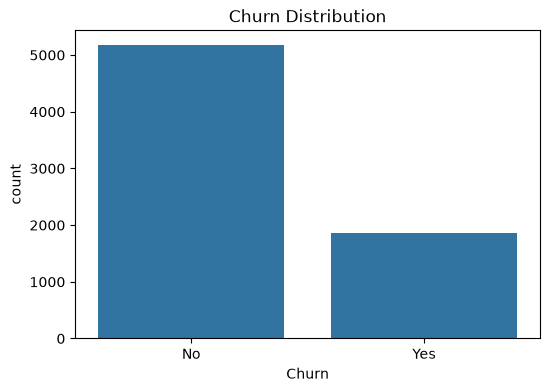

In [26]:
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

In [27]:
imbalance_ratio = churn_counts['No'] / churn_counts['Yes']
print("Imbalance ratio (No/Yes):", imbalance_ratio)

Imbalance ratio (No/Yes): 2.7683253076511503


#### 3.4 Churn % per segment

In [28]:
segments = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
            'Contract', 'PaymentMethod', 'InternetService']

for col in segments:
    churn_segment = df.groupby(col)['Churn'].value_counts(normalize=True).unstack()
    print(f"\nChurn rate by {col}:")
    print(churn_segment)


Churn rate by gender:
Churn         No       Yes
gender                    
Female  0.730791  0.269209
Male    0.738397  0.261603

Churn rate by SeniorCitizen:
Churn                No       Yes
SeniorCitizen                    
0              0.763938  0.236062
1              0.583187  0.416813

Churn rate by Partner:
Churn          No       Yes
Partner                    
No       0.670420  0.329580
Yes      0.803351  0.196649

Churn rate by Dependents:
Churn             No       Yes
Dependents                    
No          0.687209  0.312791
Yes         0.845498  0.154502

Churn rate by Contract:
Churn                 No       Yes
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319

Churn rate by PaymentMethod:
Churn                            No       Yes
PaymentMethod                                
Bank transfer (automatic)  0.832902  0.167098
Credit card (automatic)    0.847569  0.152431
El

#### 3.5 Visualize churn per segment

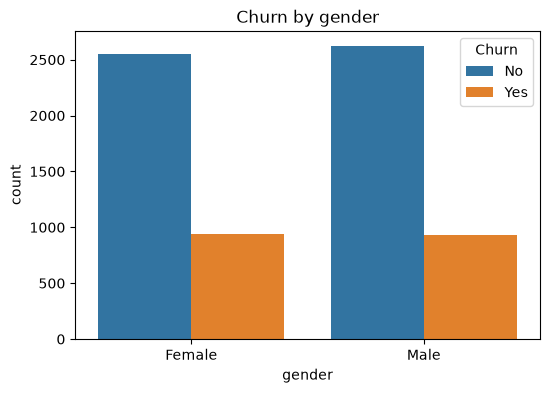

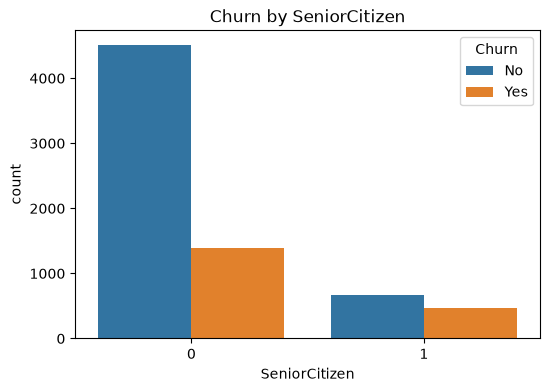

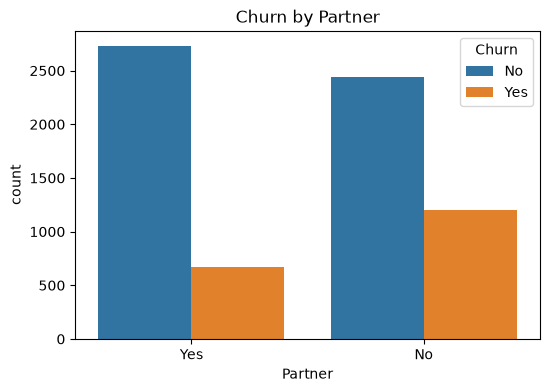

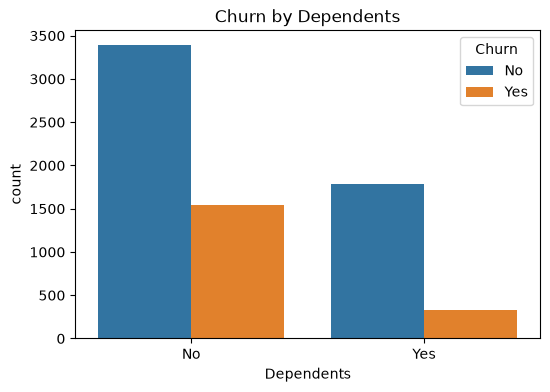

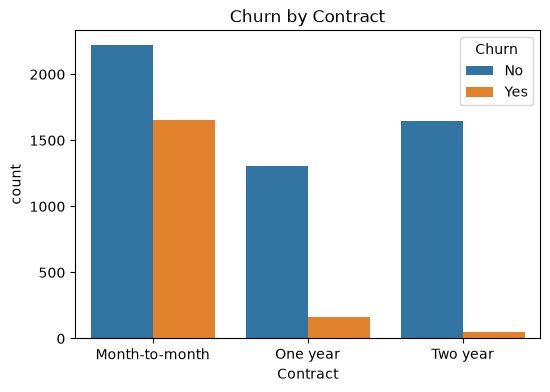

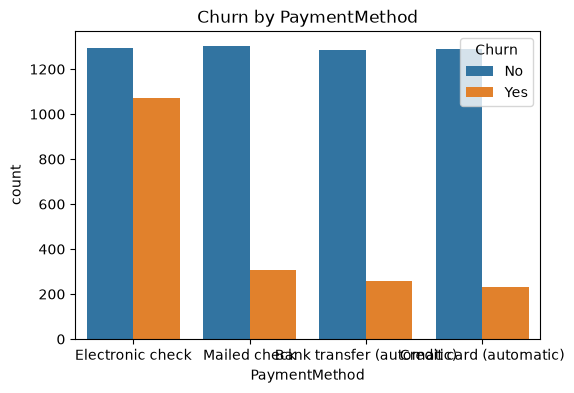

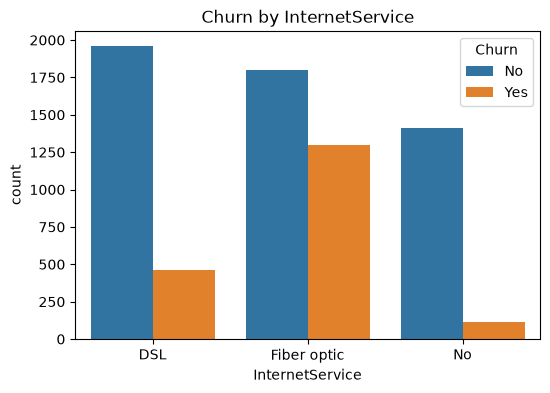

In [29]:
for col in segments:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue='Churn', data=df)
    plt.title(f'Churn by {col}')
    plt.show()

### 4. Advanced Univariate Analysis

#### 4.1 Categorizing coloumns

In [42]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[numerical_cols] = df[numerical_cols].apply(pd.to_numeric, errors='coerce')
print(df[numerical_cols].dtypes)

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


In [41]:
categorical_cols = []
for col in df.columns:
    if col not in numerical_cols and col != 'Churn' and col != 'customerID':
        categorical_cols.append(col)

In [43]:
print("Numerical columns:")
for col in numerical_cols:
    print(f"{col} ({df[col].dtype})")

print("\nCategorical columns:")
for col in categorical_cols:
    print(f"{col} ({df[col].dtype})")

Numerical columns:
tenure (int64)
MonthlyCharges (float64)
TotalCharges (float64)

Categorical columns:
gender (str)
SeniorCitizen (int64)
Partner (str)
Dependents (str)
PhoneService (str)
MultipleLines (str)
InternetService (str)
OnlineSecurity (str)
OnlineBackup (str)
DeviceProtection (str)
TechSupport (str)
StreamingTV (str)
StreamingMovies (str)
Contract (str)
PaperlessBilling (str)
PaymentMethod (str)


##### 4.1.1 Numerical features Visualization


Summary stats for tenure:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


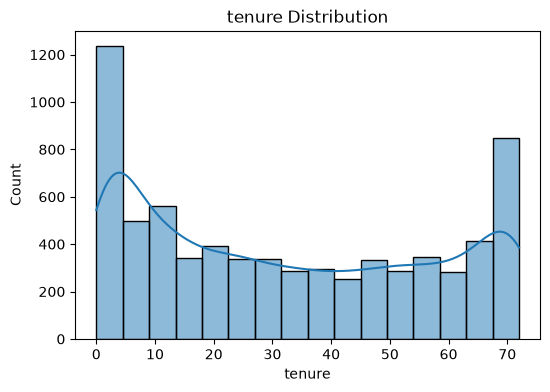

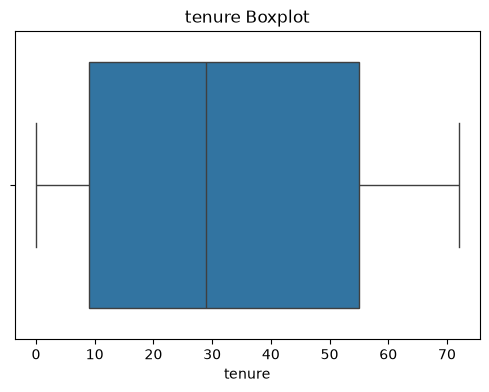


Summary stats for MonthlyCharges:
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64


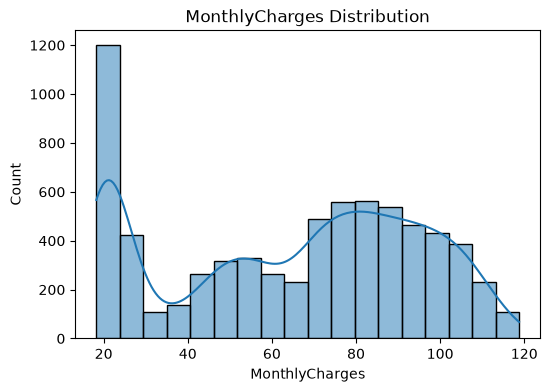

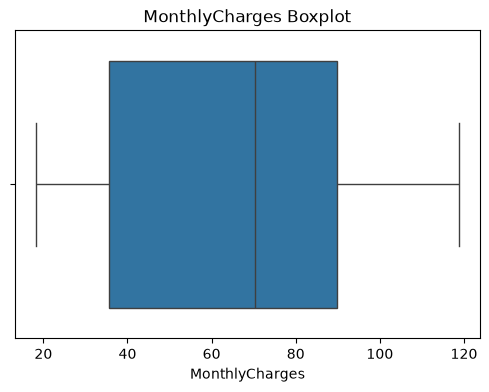


Summary stats for TotalCharges:
count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64


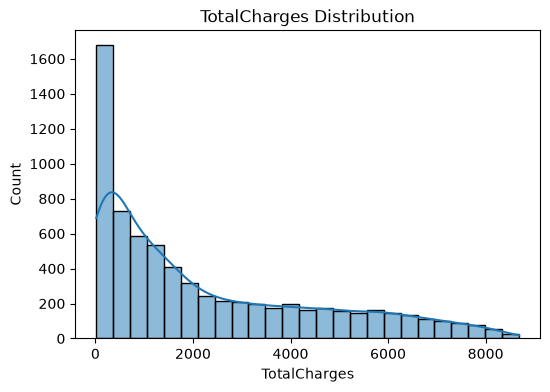

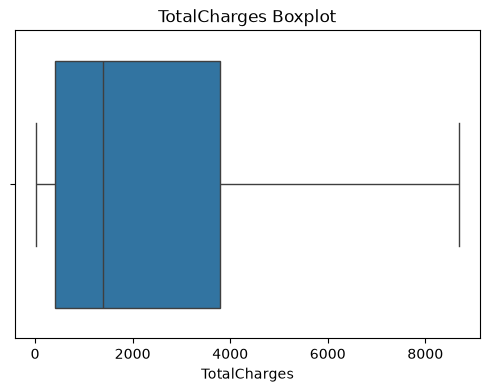

In [44]:
for col in numerical_cols:
    print(f"\nSummary stats for {col}:")
    print(df[col].describe())
    
    # Distribution plot
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'{col} Distribution')
    plt.show()
    
    # Boxplot for outlier detection
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f'{col} Boxplot')
    plt.show()

##### 4.1.2 IQR method

In [45]:
def detect_outliers_iqr(data):
    
  numeric_data = pd.to_numeric(data, errors='coerce')

  Q1 = numeric_data.quantile(0.25)
  Q3 = numeric_data.quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = (numeric_data < lower_bound) | (numeric_data > upper_bound)
  return outliers, lower_bound, upper_bound, IQR


for col in numerical_cols:
  outliers, lower, upper, iqr = detect_outliers_iqr(df[col])
  print(f'\n--- {col} ---')
  print(f'IQR: {iqr:.2f} | Bounds: [{lower:.2f}, {upper:.2f}]')
  print(f'Outliers count: {outliers.sum()} ({outliers.mean() * 100:.2f}%)')


--- tenure ---
IQR: 46.00 | Bounds: [-60.00, 124.00]
Outliers count: 0 (0.00%)

--- MonthlyCharges ---
IQR: 54.35 | Bounds: [-46.02, 171.38]
Outliers count: 0 (0.00%)

--- TotalCharges ---
IQR: 3393.29 | Bounds: [-4688.48, 8884.67]
Outliers count: 0 (0.00%)


##### 4.1.3 Z-score Method

In [46]:
def detect_outliers_zscore(data, threshold=3):

    numeric_data = pd.to_numeric(data, errors='coerce')

    mean = numeric_data.mean()
    std = numeric_data.std()

    if std == 0 or pd.isna(std):
        outliers = pd.Series(False, index=numeric_data.index)
        return outliers, mean, mean, threshold

    z_scores = (numeric_data - mean) / std

    lower_bound = mean - threshold * std
    upper_bound = mean + threshold * std

    outliers = (z_scores > threshold) | (z_scores < -threshold)

    return outliers, lower_bound, upper_bound, threshold


for col in numerical_cols:
    outliers, lower, upper, threshold = detect_outliers_zscore(df[col])

    print(f'\n--- {col} ---')
    print(f'Z-score threshold: ±{threshold}')
    print(f'Bounds: [{lower:.2f}, {upper:.2f}]')
    print(f'Outliers count: {outliers.sum()} ({outliers.mean() * 100:.2f}%)')


--- tenure ---
Z-score threshold: ±3
Bounds: [-41.31, 106.05]
Outliers count: 0 (0.00%)

--- MonthlyCharges ---
Z-score threshold: ±3
Bounds: [-25.51, 155.03]
Outliers count: 0 (0.00%)

--- TotalCharges ---
Z-score threshold: ±3
Bounds: [-4517.01, 9083.61]
Outliers count: 0 (0.00%)


#### 4.2 Categorical features Visualization


Value counts for gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64


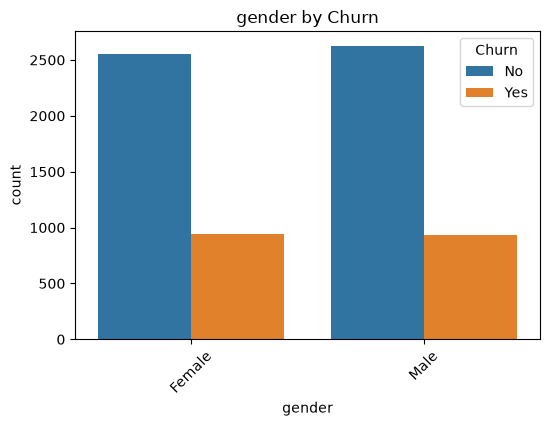


Value counts for SeniorCitizen:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


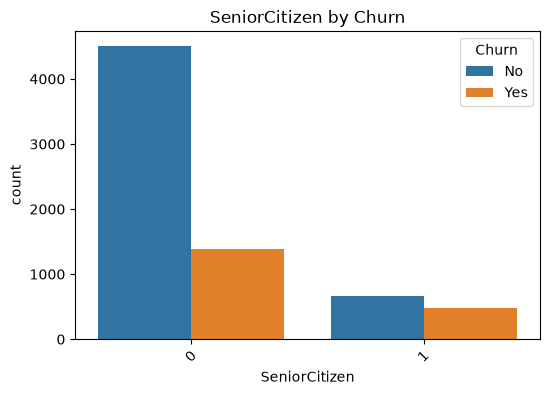


Value counts for Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64


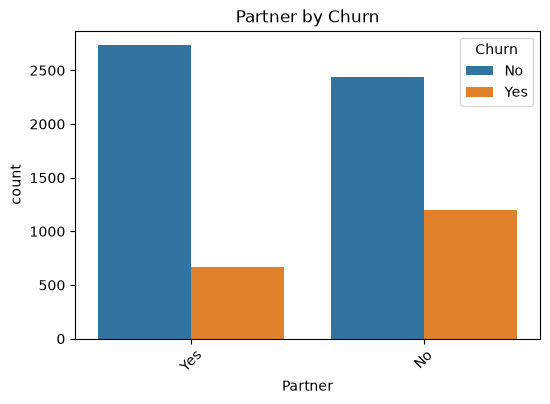


Value counts for Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64


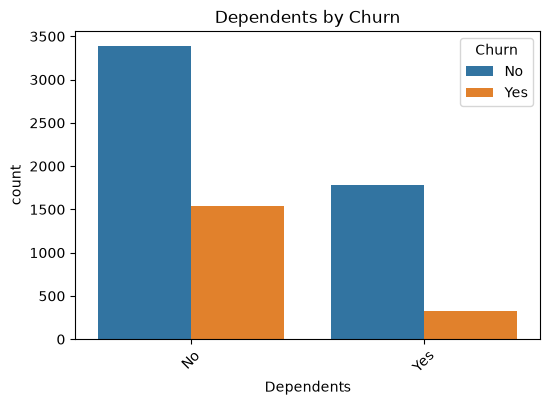


Value counts for PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64


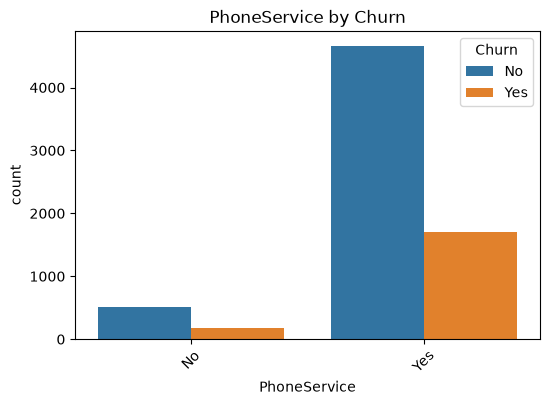


Value counts for MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


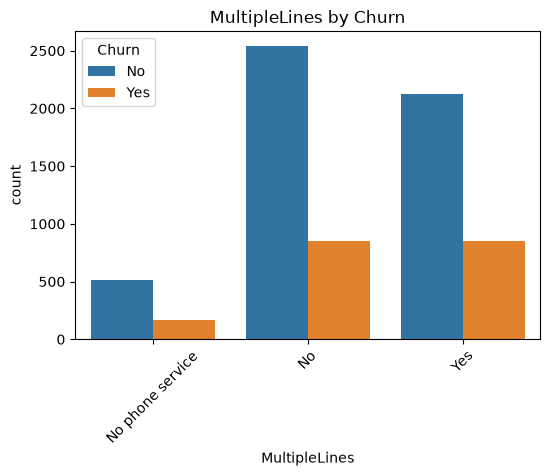


Value counts for InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


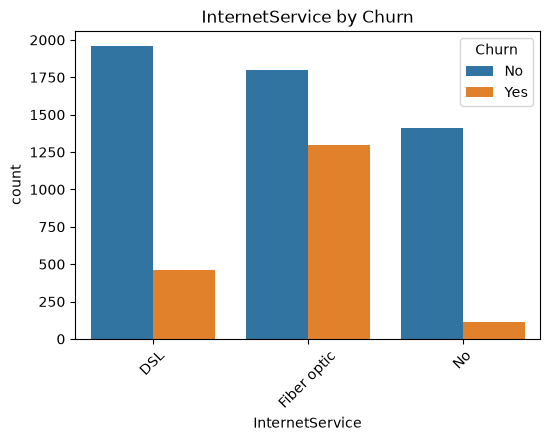


Value counts for OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


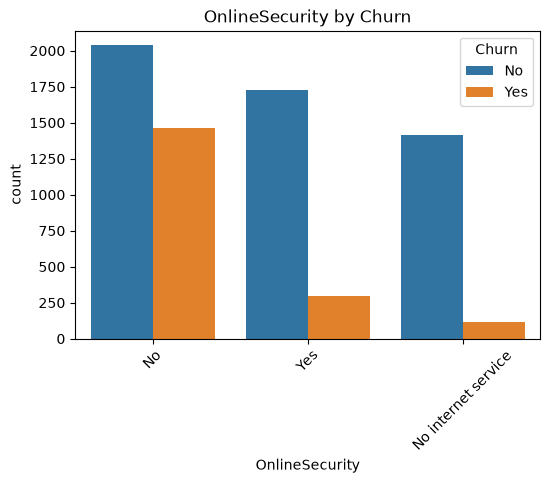


Value counts for OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64


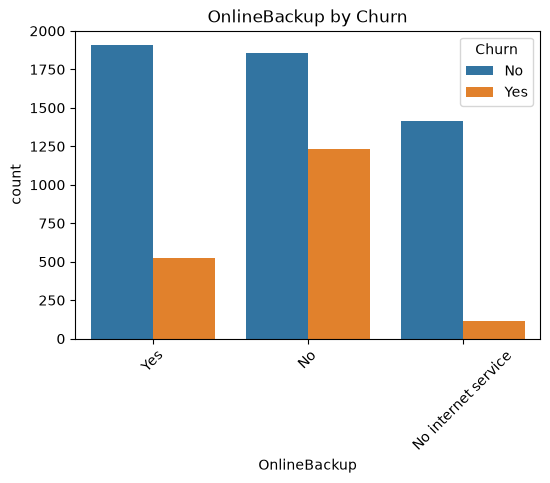


Value counts for DeviceProtection:
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64


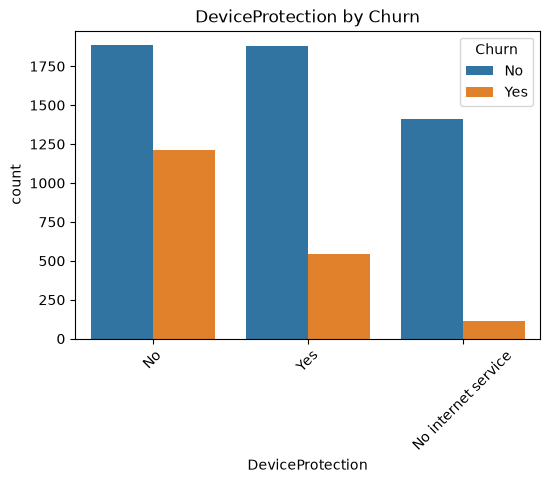


Value counts for TechSupport:
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64


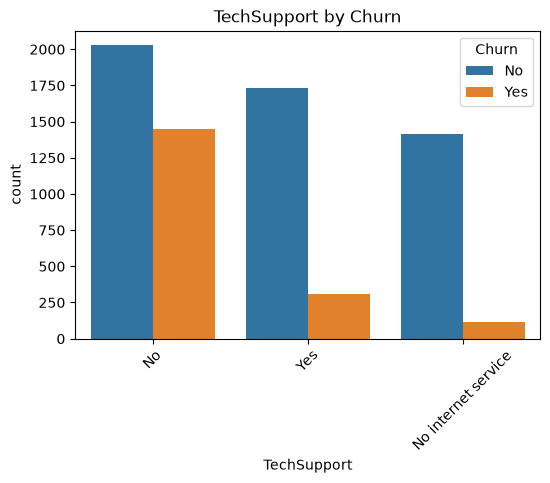


Value counts for StreamingTV:
StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64


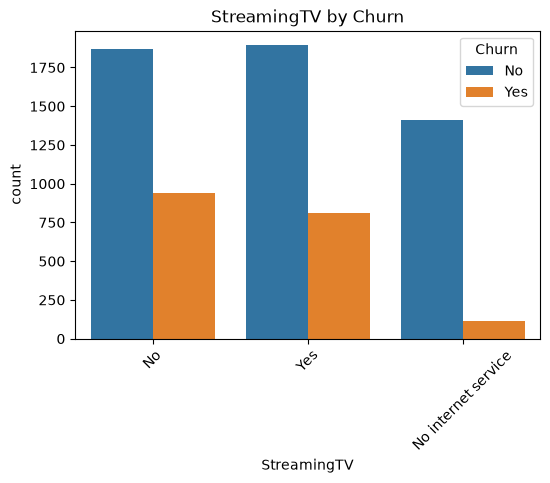


Value counts for StreamingMovies:
StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64


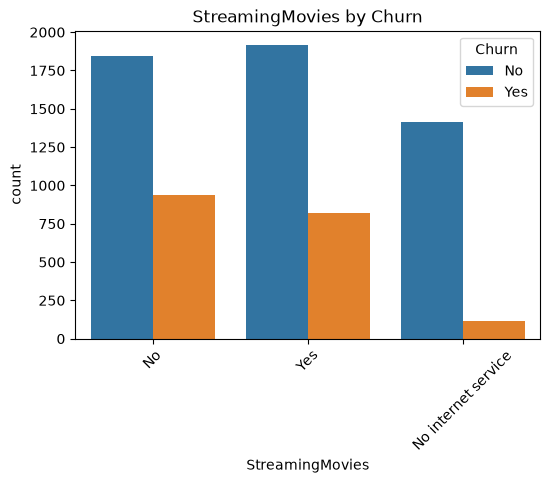


Value counts for Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


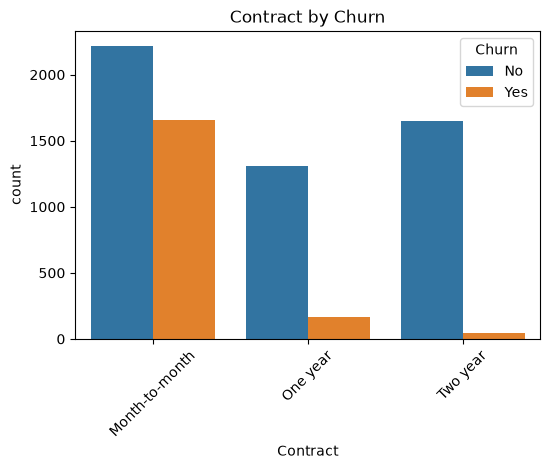


Value counts for PaperlessBilling:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64


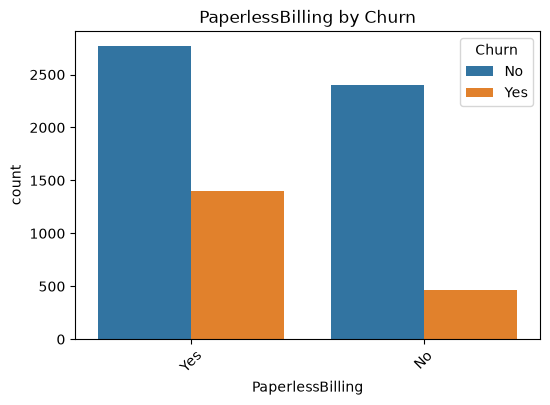


Value counts for PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


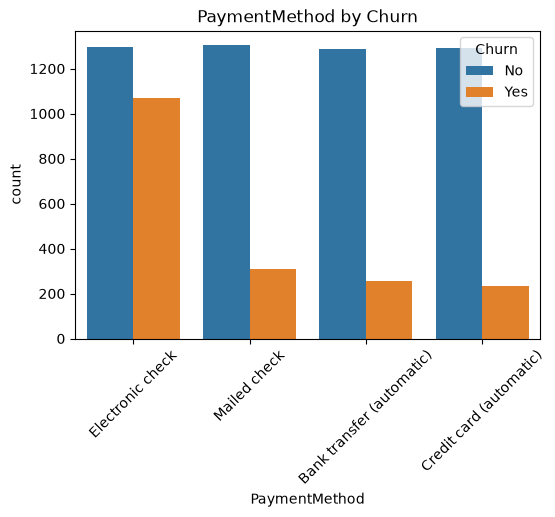

In [35]:
for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())
    
    # Bar plot with churn hue
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue='Churn', data=df)
    plt.title(f'{col} by Churn')
    plt.xticks(rotation=45)
    plt.show()

In [36]:
for col in categorical_cols:
    freq = df[col].value_counts(normalize=True)
    rare = freq[freq < 0.01]  # categories <1% of data
    if not rare.empty:
        print(f"{col} has rare categories:\n{rare}")

In [37]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [38]:
df = df.drop(columns=['z_tenure', 'z_MonthlyCharges', 'z_TotalCharges'], errors='ignore')